# Phase 1 - Convolutional Neural Networks

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.

Section 5 asks you to run different hyperparameters- please make sure to run all your codes and make sure outputs are neat enough to read.

You may find [this](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) Pytorch tutorial helpful.

## **Overview**
1. Loading & Visualizing Data
2. Utility Functions
3. Define CNNs
4. Train and Evaluate
5. Experiments and Reporting

In [6]:
# Run to import necessary libraries
import time
import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

In [12]:
# Set seeds to make random operations more reproducible.
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
# Use the first CUDA GPU when available, otherwise use the CPU.
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
# Show where training will run.
print('Device:', device)

Device: cpu


# **1. Loading & Visualizing Data**

Please use MNIST for this phase. MNIST is a digit classification dataset, with greyscale 28x28 images, and 10 classes (numbers 0-9).

See [documentation.](https://pytorch.org/vision/0.15/generated/torchvision.datasets.MNIST.html) You can also see the `MNIST_Tutorial.ipynb`.

Please complete loading the data below.

Please also complete `show_imgs()`. Function should input the dataloader, and show 10 random images and their labels.

In [18]:
# Section 1: load the official training and test splits separately.
# Use a workspace-relative directory, as in Lab3Part2.

train_data = datasets.MNIST('./mnist_data', train=True,
                            transform=transforms.ToTensor(), download=True)
test_data = datasets.MNIST('./mnist_data', train=False,
                           transform=transforms.ToTensor(), download=True)

batch_size = 32

# Construct matching loaders for the batch size
def make_loaders(batch_size):
    generator = torch.Generator().manual_seed(SEED)
    return (
        torch.utils.data.DataLoader(train_data, batch_size=batch_size,
                                    shuffle=True, generator=generator),
        torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=False)
    )

train_loader, test_loader = make_loaders(batch_size)
print(f'Train: {len(train_data)}, test: {len(test_data)}')

Train: 60000, test: 10000


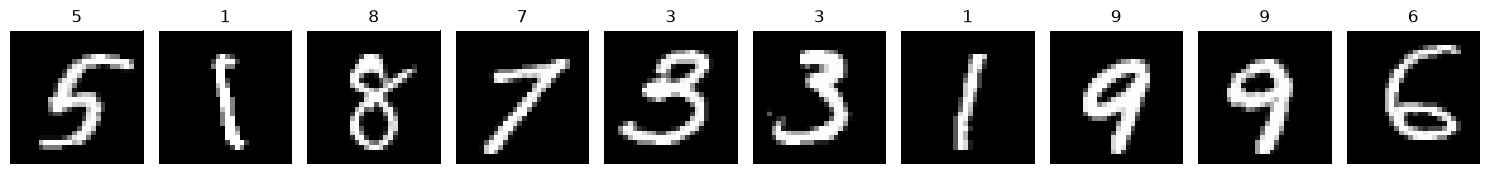

In [20]:
# Function should input the dataloader, and show random 10 images and their labels as title to plot
def show_imgs(dataloader):
    # sample the dataset directly so this also works with batch size 8
    indices = torch.randperm(len(dataloader.dataset))[:10].tolist()
    fig, axes = plt.subplots(1, len(indices), figsize=(15, 2), squeeze=False)
    # give each sampled image its own subplot.
    for ax, index in zip(axes.ravel(), indices):
        #  Get the image and its label
        image, label = dataloader.dataset[index]
        # Remove the extra channel dimension and show the image in grayscale
        ax.imshow(image.squeeze(0).cpu().numpy(), cmap='gray', vmin=0, vmax=1)
        # Put the correct label above the image
        ax.set_title(str(label))
        # hide pixel coordinate axes
        ax.axis('off')
    # Adjust subplot spacing
    fig.tight_layout()
    plt.show()

show_imgs(train_loader)

## **2. Utility Functions**

Please complete `train()` and `plot_learning_curves()` functions. `test_accuracy()` has already been provided to you.

In [9]:
def test_accuracy(model, test_loader, input_size, device):
    model.to(device)
    correct = 0
    total = 0
    with torch.no_grad():
        for test_data in test_loader:
            images, labels = test_data[0].cuda(), test_data[1].cuda()
            images = images.view(-1, input_size)
            outputs = net(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    print('Accuracy: %d %%' % (100 * correct / total))


## **2.1 Train Function**
Please refer to the train function in `MNIST_Classifier.ipynb` to complete this function.
- You will need to store the loss and accuracies per iteration (to plot later). Do this for both the train set and test set!
- Please print the loss, accuracy and time taken **each epoch** for both train and test sets

In [22]:
def train(model, loss_fn, optimizer, train_loader, test_loader, batch_size, num_epochs, device):
     # Move the model to the same CPU or GPU as the images.
    model.to(device)
    history = {key: [] for key in (
        'train_loss', 'test_loss', 'train_accuracy', 'test_accuracy', 'train_batch_loss', 'train_batch_accuracy',
        'test_batch_loss', 'test_batch_accuracy', 'train_seconds', 'test_seconds')}

    # Wait for the GPU to finish before measuring the time.
    def sync():
        # The GPU may still be working, so wait until it finishes.
        if device.type == 'cuda':
            torch.cuda.synchronize(device)

    # Train on all training batches, then check all test batches each epoch.
    for epoch in range(num_epochs):
        # Switch to training mode so batch normalization can update its statistics.
        model.train()
        sync()
        # Start timing this part.
        start = time.perf_counter()
        # Start the loss and image counts at zero.
        loss_sum = correct = total = 0
        # Train one batch at a time.
        for images, labels in train_loader:
            # Move the images and labels to the CPU or GPU we chose.
            images, labels = images.to(device), labels.to(device)
            # Clear the old gradients before calculating new ones.
            optimizer.zero_grad(set_to_none=True)
            # Pass the images through the model to get its predictions.
            outputs = model(prepare_images(model, images))
            # Calculate the loss using the model scores and correct labels.
            loss = loss_fn(outputs, labels)
            # Calculate the gradients with backpropagation.
            loss.backward()
            # Let the optimizer update the weights.
            optimizer.step()
            # Count the images in this batch. The last batch might be smaller.
            n = labels.size(0)
            # Pick the digit with the highest score and count the correct answers.
            hits = (outputs.argmax(1) == labels).sum().item()
            # Multiply by the batch size so smaller batches get the right weight in the average.
            loss_sum += loss.item() * n
            # Add the correct predictions to our total.
            correct += hits
            # Add the number of images to our total.
            total += n
            # Save this batch's loss as a regular number.
            history['train_batch_loss'].append(loss.item())
            # Save this batch's training accuracy.
            history['train_batch_accuracy'].append(100 * hits / n)
        sync()
        train_seconds = time.perf_counter() - start
        # Start timing this part.
        start = time.perf_counter()
        test_loss, test_acc, losses, accuracies = evaluate(
            model, test_loader, loss_fn, device, per_batch=True)
        sync()
        test_seconds = time.perf_counter() - start
        for key, value in (
            ('train_loss', loss_sum / total), ('train_accuracy', 100 * correct / total),
            ('test_loss', test_loss), ('test_accuracy', test_acc),
            ('train_seconds', train_seconds), ('test_seconds', test_seconds)):
            history[key].append(value)
        # Save the test batch losses together for this epoch.
        history['test_batch_loss'].append(losses)
        # Save the test batch accuracies for this epoch too.
        history['test_batch_accuracy'].append(accuracies)
        print(f'Epoch {epoch + 1:2d}/{num_epochs} | '
              f'Train loss {loss_sum / total:.4f}, acc {100 * correct / total:.2f}%, '
              f'time {train_seconds:.2f}s | Test loss {test_loss:.4f}, '
              f'acc {test_acc:.2f}%, time {test_seconds:.2f}s')
    return history

## **2.2 Plot Learning Curves Function**
Plot the loss and accuracies from training. Example outputs will be provided in lab walkthrough.

In [11]:
def plot_learning_curve(''' TODO '''):
    ''' TODO '''

SyntaxError: invalid syntax (660178213.py, line 1)

# **3. Define CNNs**

A 1-Layer Architecture is already defined for you (`Net`) as a reference. Please complete the definitions of the 2-Layer CNN (`Net2`). The network architecture definitions are provided to you. You must calculate some dimensions yourself.

**NOTE:** For now, please use ReLU activation. You will experiment with other activations in Section 5.

In [ ]:
class Net(nn.Module):
    def __init__(self, input_size, num_classes):
        super(Net,self).__init__()
        self.fc1 = nn.Linear(input_size, 500)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(500, num_classes)

    def forward(self,x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

## **3.1 Create a 2-Layer CNN**
Complete `Net2` class.

 Network Architecture:
* ***Layer 1 (Input)***: Convolutional; input channel = 1, output channel = 20, kernel size = 3, step size = 1.
* ***Layer 2 (Output)***: Fully connected; input dimension = < you find out >, output dimension = < you find out >.

In [ ]:
# Define 2-Layer Network
class Net2(nn.Module):
    ''' TODO '''

# **4. Train and Evaluate**

## **4.1 Training and Evaluating 1-Layer CNN**

Here, you must test your utility functions (`train()` and `plot_learning_curves()`)with the 1-Layer Model. Please at this stage ensure your utility functions are working correctly. The TAs will provide sample outputs in lab walkthrough.

**NOTE**: You can repeatedly use this below code block in Section 5 to run experiments, while making changes to the hyperparameters as required.

In [ ]:
# Define Parameters
input_size = ''' TODO ''''
num_classes = ''' TODO '''
lr = 0.01
num_epochs = 10

# Instantiate 1-Layer Model
net = Net(input_size, num_classes)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

# Train Model
train(''' TODO ''')

# Plot Learning Curves
plot_learning_curve(''' TODO ''')

# Evaluate on Test Set
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

## **4.2 Training and Evaluating 2-Layer CNN**


Please also train your 2-Layer network to ensure it is working properly.

In [ ]:
# Define Parameters
input_size = ''' TODO ''''
num_classes = ''' TODO '''
lr = 0.01
num_epochs = 10

# Instantiate 1-Layer Model
net = Net2(''' TODO ''')
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
net.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr)

# Train Model
train(''' TODO ''')

# Plot Learning Curves
plot_learning_curve(''' TODO ''')

# Evaluate on Test Set
test_accuracy(model=net, test_loader=test_loader, input_size=input_size)

# **5. Experiments and Reporting**

In this section, you'll use the utility functions and model definitions from earlier to test various scenarios. You'll modify hyperparameters, run training, plot results, and analyze performance. Based on your observations, you'll answer specific questions.

Use the provided loss, accuracy, and learning curves to address the report questions for each subsection.

**Note:** You will primarily reuse functions from earlier sections. Make any necessary code changes in the sections marked `# YOUR CODE HERE`.

## **5.1 Learning Curves**

### **❓ Q 5.1.1 What is a Learning curve and why is it useful? You can refer to learning curves you have plotted in Section 4.** (you do not need to run any codes here)

ANSWER HERE

---

### **5.2 Learning Rates**

Please plot the curves for three separate training instances with learning rates of: `2e-3`, `3e-4`, `5e-2 `

Use the 2-Layer CNN.

In [ ]:
# 2e-3
# YOUR CODE HERE

In [ ]:
# 3e-4
# YOUR CODE HERE

In [ ]:
# 5e-2
# YOUR CODE HERE

### ❓ **Q 5.2.1 For each learning rate, explain if the model is underfitting, overfitting, or is training well. Explain the difference between high learning rates and low learning rates in terms of the optimization process.**

ANSWER HERE

---

### **5.3 Optimizer**
The optimizer we have used before is Adam. Change the optimizer to:
- **Stochastic gradient descent ([SGD](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html))**
- **SGD with momentum:** try momentum 0.5 and 0.9.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

In [ ]:
# SGD
# YOUR CODE HERE

In [ ]:
# SGD 0.5
# YOUR CODE HERE

In [ ]:
# SGD 0.9
# YOUR CODE HERE

#### ❓ **Q 5.3.1 Explain the differences in Adam and both SGD optimizations. Compare the results of each optimizer based on the learning curves.**

ANSWER HERE

---

### **5.4 Initializing Weights**

Initialize the weights to:
- all zeros
- all ones
- all randomly initialized with a normal distribution.

Use 2-Layer CNN.

In [ ]:
# All zeros
# YOUR CODE HERE

In [ ]:
# All ones
# YOUR CODE HERE

In [ ]:
# Random
# YOUR CODE HERE

#### ❓ **Q 5.4.1 How is the training process affected when we initialize our network weights differently? Based on what you observe, give a recommendation as to how weights should be initialized. Explain your reasoning.**

(Note: your results may not reflect what is expected. Please explain what is expected and why your results may not reflect that.)

ANSWER HERE

---

### **5.5 Activation Function**

Please change the `relu` function in the example code to a `tanh` function.

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

In [ ]:
# YOUR CODE HERE

#### ❓ **Q 5.5.1 How does changing the activation function to tanh affect the performance? Is it better or worse? Explain why.**

ANSWER HERE

---

### **5.6 Batch Size**

Test training using different batch sizes to compare. Please use batch size of:
- 8
- 64
- 128

Use 2-Layer CNN. Keep all other hyperparameters constant. You can use the best from earlier experiments.

In [ ]:
# Batch size 8
# YOUR CODE HERE

In [ ]:
# Batch size 64
# YOUR CODE HERE

In [ ]:
# Batch size 128
# YOUR CODE HERE

#### ❓ **Q 5.6.1 How does changing batch size affect the training process?**

ANSWER HERE

---

### 5.7 Different Network Architectures

Please complete the `Net5` and `FCN` definitions. The archtiectures are defined below.


#### **5.7.1 Net5: 5-Layer CNN**
Similar to the 2-Layer model, make a new class ```Net5```.

* ***Layer 1 (Input)***: Convolutional, input channel = 1, output channel = 32, kernel size = 5, stride = 1, padding = 2.
* ***Layer 2 (Hidden 1)***: Pooling, kernel size = 2, stride = 2.
* ***Layer 3 (Hidden 2)***: Convolutional, input channel = < you find out> , output channel = 64, kernel size = 5, stride = 1 padding = 2.
* ***Layer 4 (Hidden 3)***: Fully connected, input channel = < you find out>, output channel = 1024.
* ***Layer 5 (Output)***: Fully connected, input channel = < you find out>, < you find out >

In [ ]:
# YOUR CODE HERE (NET5)

# ...

# Define 5-Layer Network
class Net5(nn.Module):
    ''' TODO '''

# ...

#### **5.7.2 FCN**

Here we will define a Fully Connected Network `FCN` (Not a CNN).

- **Layer 1 (Input):** Size = < you find out >
- **Layer 2 (Hidden 1):** 256 neurons
- **Layer 3 (Hidden 2):** 256 neurons
- **Layer 4 (Output):** Size = < you find out >

In [ ]:
# YOUR CODE HERE (FCN)

# ...

# Define FCN
class FCN(nn.Module):
    ''' TODO '''

# ...

#### **5.7.3 Training the different architectures**

Train and evaluate `Net2`, `Net5`, and `FCN` using batch size of 64, the best learning rate from Section 5.1, and the best optimizer from Section 5.5


In [ ]:
# Net2
# YOUR CODE HERE

In [ ]:
# Net5
# YOUR CODE HERE

In [ ]:
# FCN
# YOUR CODE HERE

#### ❓ **Q 5.7.4 Explain which model is better and why. Use your learning curves as well as what you know about model capacity to explain your reasoning.** If you think your results do not reflect the best model, explain which you expect to be best and why.

YOUR ANSWER HERE

#### ❓ **Q 5.7.5 Which model converges to a minimum faster? Why? What hyperparameters would you tune in order to get a model to converge faster?**

YOUR ANSWER HERE

#### ❓ **Q 5.7.6 Explain the purpose of the pooling layer**

YOUR ANSWER HERE

#### ❓ **Q 5.7.7  Is it possible for a model to have a smaller final loss, even if it has worse test accuracy.**

YOUR ANSWER HERE

#### ❓ **Q 5.7.8 Explain the difference between the CNN models and FCN.**

YOUR ANSWER HERE


---



### **5.8 Batch Normalization**

Choose the model that performs the best (`Net`, `Net2`, `Net5`, `FCN`). Add batch normalization layers where you see fit. Repeat and train and plot learning curves.



In [ ]:
# YOUR CODE HERE

#### ❓ **Q 5.8 Explain the purpose of the batch normalization layers,and how they affect training.**

YOUR ANSWER HERE

---
---

# End of Phase 1 😊🥳